##TP3 — Preprocesamiento de tweets

Preparar los textos del dataset Sentiment140 para utilizarlos en los modelos de clasificación de sentimientos.

In [39]:
import pandas as pd
from pathlib import Path
from google.colab import drive
import subprocess

USAR_MUESTRA = True
carpeta_proyecto = Path("/content/diploup2026-TP3")
if not (carpeta_proyecto / ".git").exists():
    subprocess.run(["git", "clone","https://github.com/nachopedretti/diploup2026-TP3.git",str(carpeta_proyecto)],check=True)

if not USAR_MUESTRA:
    drive.mount("/content/drive")

ruta_muestra = carpeta_proyecto / "datos" / "muestras" / "tweets_muestra_100k.csv"

ruta_original = Path(
    "/content/drive/MyDrive/DiploIA/TP3/trainingandtestdata/training.1600000.processed.noemoticon.csv")

print("Repositorio:", carpeta_proyecto)
print("Muestra disponible:", ruta_muestra.exists())
if not USAR_MUESTRA:
    print("Dataset original disponible:", ruta_original.exists())

Repositorio: /content/diploup2026-TP3
Muestra disponible: True


# Conjunto de datos


In [40]:
columnas = ["sentimiento", "ID", "fecha", "consulta", "usuario", "texto"]
if USAR_MUESTRA:
    df_entrenamiento = pd.read_csv(
        ruta_muestra,
        encoding="utf-8")
    print("Muestra cargada desde GitHub")

else:
    df_entrenamiento = pd.read_csv(
        ruta_original,
        encoding="latin-1",
        header=None,
        names=columnas)
    print("Dataset completo cargado desde Google Drive")
# Unificar el nombre de la columna ID
df_entrenamiento = df_entrenamiento.rename(columns={"id": "ID"})
print("Dimensiones:", df_entrenamiento.shape)
print("Columnas:", df_entrenamiento.columns.tolist())

Muestra cargada desde GitHub
Dimensiones: (100000, 6)
Columnas: ['sentimiento', 'ID', 'fecha', 'consulta', 'usuario', 'texto']


In [41]:
# Seleccionar las columnas necesarias para el preprocesamiento
df_procesamiento = df_entrenamiento[
    ["texto", "sentimiento"]].copy()

# Registrar las características del dataset inicial
total_original = len(df_procesamiento)

distribucion_original = (
    df_procesamiento["sentimiento"]
    .value_counts()
    .sort_index())

# Identificar el dataset utilizado
tipo_dataset = "Muestra" if USAR_MUESTRA else "Completo"

print("Dataset utilizado:", tipo_dataset)
print("Dimensiones:", df_procesamiento.shape)
print("Cantidad original de tweets:", total_original)

print("\nDistribución original de sentimientos:")
display(distribucion_original)

print("\nEjemplos:")
display(df_procesamiento.head())

Dataset utilizado: Muestra
Dimensiones: (100000, 2)
Cantidad original de tweets: 100000

Distribución original de sentimientos:


,count
sentimiento,
0,50000
4,50000



Ejemplos:


,texto,sentimiento
0,15th piece for Neuwerld sent and waiting appro...,4
1,no twat for 2 days! must have gotten my ass ki...,4
2,We're getting several confirmations that some ...,0
3,Please follow!!,4
4,getting ready to have coffee with a good friend,4


# Identificar textos duplicados


In [4]:
duplicados = df_procesamiento["texto"].duplicated().sum()
sentimientos_por_texto = (
    df_procesamiento.groupby("texto")["sentimiento"].nunique())

textos_contradictorios = (sentimientos_por_texto > 1).sum()

print("Textos duplicados:", duplicados)
print("Textos con sentimientos contradictorios:", textos_contradictorios)

Textos duplicados: 318
Textos con sentimientos contradictorios: 22


#Seleccionar 10 textos contradictorios

In [5]:
ejemplos_contradictorios = sentimientos_por_texto[
    sentimientos_por_texto > 1
].sample(n=min(10, int((sentimientos_por_texto > 1).sum())), random_state=42).index

ejemplos = df_entrenamiento[
    df_entrenamiento["texto"].isin(ejemplos_contradictorios)]

for texto, grupo in ejemplos.groupby("texto"):
    print("Texto:", texto)
    print("Sentimientos:", sorted(grupo["sentimiento"].unique()))
    print("-" * 60)

Texto: #jaljeera can't beat #followfriday  More People know Friday than Jaljeera 
Sentimientos: [np.int64(0), np.int64(4)]
------------------------------------------------------------
Texto: @WH1SKS sorry   i'm in bed already. I don't sleep in clothes.... And i'm can't really take pictures of invisi-knickers 
Sentimientos: [np.int64(0), np.int64(4)]
------------------------------------------------------------
Texto: @jolliehaybowes You looked really pretty at soap awards! And your scene was only one tht made everyone laugh! You should have won   x
Sentimientos: [np.int64(0), np.int64(4)]
------------------------------------------------------------
Texto: @leolodreamland shame about the weather today tho ..  v.v. soggy! 
Sentimientos: [np.int64(0), np.int64(4)]
------------------------------------------------------------
Texto: @tommcfly 
Sentimientos: [np.int64(0), np.int64(4)]
------------------------------------------------------------
Texto: Back to work. 
Sentimientos: [np.int64(0)

### Textos con sentimientos contradictorios

- Tenemos 2.225 textos etiquetados como positivos como negativos
- Algnos ehjempos, contienen frases ambiguas, que pueden interpretarse de distintas maneras y algunos que pueden ser errores de etiquetado
- Por estas razones se decidió excluir todo estos textos para evitar contradicciones durante el entrenamiento y la evaluación de los modelos

#### Datos originales > Suprimir textos con sentimiento contradictorio

In [42]:
df_procesamiento = df_entrenamiento[
    ["texto", "sentimiento"]].copy()

sentimientos_por_texto = (
    df_procesamiento.groupby("texto")["sentimiento"].nunique())

textos_a_excluir = sentimientos_por_texto[
    sentimientos_por_texto > 1].index

print("Textos contradictorios identificados:", len(textos_a_excluir))

df_procesamiento = df_procesamiento[
    ~df_procesamiento["texto"].isin(textos_a_excluir)
].copy()

# Verificar los resultados
print("Registros originales:", len(df_entrenamiento))
print("Registros eliminados:", len(df_entrenamiento) - len(df_procesamiento))
print("Registros restantes:", len(df_procesamiento))

print("Textos contradictorios restantes:",
    (df_procesamiento.groupby("texto")["sentimiento"].nunique() > 1).sum())

print("Textos duplicados restantes:",
    df_procesamiento["texto"].duplicated().sum())

total_sin_contradicciones_originales = len(df_procesamiento)

Textos contradictorios identificados: 22
Registros originales: 100000
Registros eliminados: 54
Registros restantes: 99946
Textos contradictorios restantes: 0
Textos duplicados restantes: 286


### Resumen de textos eliminados y textos restantes

In [43]:
duplicados_antes = df_procesamiento["texto"].duplicated().sum()

df_procesamiento = df_procesamiento.drop_duplicates(
    subset=["texto"]).reset_index(drop=True)

print("Duplicados eliminados:", duplicados_antes)
print("Registros restantes:", len(df_procesamiento))
print("Textos duplicados restantes:",
      df_procesamiento["texto"].duplicated().sum())

print("\nDistribución de sentimientos:")
print(df_procesamiento["sentimiento"].value_counts())

total_sin_duplicados_originales = len(df_procesamiento)

Duplicados eliminados: 286
Registros restantes: 99660
Textos duplicados restantes: 0

Distribución de sentimientos:
sentimiento
4    49864
0    49796
Name: count, dtype: int64


### **Resultados, reducimos el riesgo de dataleakage**
- De 1.600.000 tweets eliminamos 6.895, asociados a sentimientos contradictorios y 13.864 duplicados.

- Después de esta limpieza quedaron 1.579.241 tweets únicos.

- La distribución de sentimientos se mantiene: 787.960 negativos y 791.281 positivos

# **Limpieza de tweets, htmls a caracteres normales, convertir a minúsculas, urls, eliminar menciones de usuarios y espacios repetidos.**

In [44]:
import re
import html

def limpiar_texto(texto):

    texto = html.unescape(texto)
    texto = texto.lower()
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)
    texto = re.sub(r"@\w+", " ", texto)
    texto = re.sub(r"#(\w+)", r"\1", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

# Probar la función con un ejemplo
texto_ejemplo = "@usuario I don't like this! But I love #music :) https://example.com"

print("Original:", texto_ejemplo)
print("Limpio:", limpiar_texto(texto_ejemplo))

Original: @usuario I don't like this! But I love #music :) https://example.com
Limpio: i don't like this! but i love music :)


## Limpieza a todos los tweets


In [9]:
df_procesamiento["texto_limpio"] = (
    df_procesamiento["texto"].apply(limpiar_texto))

# Verificar los resultados
print("Tweets procesados:", len(df_procesamiento))
print("\nEjemplos de limpieza:")
display(df_procesamiento[["texto", "texto_limpio", "sentimiento"]].head(10))

Tweets procesados: 99660

Ejemplos de limpieza:


,texto,texto_limpio,sentimiento
0,15th piece for Neuwerld sent and waiting appro...,15th piece for neuwerld sent and waiting appro...,4
1,no twat for 2 days! must have gotten my ass ki...,no twat for 2 days! must have gotten my ass ki...,4
2,We're getting several confirmations that some ...,we're getting several confirmations that some ...,0
3,Please follow!!,please follow!!,4
4,getting ready to have coffee with a good friend,getting ready to have coffee with a good friend,4
5,Finally starting to get the hang of this thing...,finally starting to get the hang of this thing...,4
6,just listed the first few items in her new ets...,just listed the first few items in her new ets...,4
7,dropped my phone in the water.. oooohh yaaaay....,dropped my phone in the water.. oooohh yaaaay....,4
8,leaving for DC in 2 hours. so pumped twitter ...,leaving for dc in 2 hours. so pumped twitter i...,4
9,@twilightfairy but you have a watermark on the...,but you have a watermark on the images! everyo...,4


Revición de duplicados post limpieza, ver sentimientos contradictorios

In [10]:
duplicados_limpios = (
    df_procesamiento["texto_limpio"].duplicated().sum())
sentimientos_limpios = (
    df_procesamiento
    .groupby("texto_limpio")["sentimiento"]
    .nunique())
contradictorios_limpios = (sentimientos_limpios > 1).sum()
textos_vacios = (
    df_procesamiento["texto_limpio"].eq("").sum())

print("Textos duplicados después de la limpieza:", duplicados_limpios)
print("Textos con sentimientos contradictorios:", contradictorios_limpios)
print("Textos vacíos después de la limpieza:", textos_vacios)

Textos duplicados después de la limpieza: 1279
Textos con sentimientos contradictorios: 57
Textos vacíos después de la limpieza: 181


Analizar los textos que quedaron vacíos

In [11]:
# Seleccionar tweets que quedaron vacíos
df_vacios = df_procesamiento[
    df_procesamiento["texto_limpio"] == ""]

# Mostrar cantidad y distribución de sentimientos
print("Tweets vacíos:", len(df_vacios))

print("\nDistribución de sentimientos:")
print(df_vacios["sentimiento"].value_counts())

# Mostrar 15 ejemplos originales
print("\nEjemplos de textos originales:")
display(
    df_vacios[["texto", "texto_limpio", "sentimiento"]]
    .sample(n=min(15, len(df_vacios)), random_state=42))

Tweets vacíos: 181

Distribución de sentimientos:
sentimiento
0    93
4    88
Name: count, dtype: int64

Ejemplos de textos originales:


,texto,texto_limpio,sentimiento
10445,@CharlieFinch,,0
20804,@SweetFacePoca,,0
84586,@emceedowell,,0
42957,@CelebratedMissK,,4
80143,@make_me_scream,,4
8586,@ariyaly,,0
11609,@bethanyvarrone http://bit.ly/wKCys,,4
36313,@nothing_to_sea,,4
60020,@G2Buck,,4
62400,@wishdreamhope,,0


In [12]:
# Eliminar únicamente los textos vacíos
registros_antes = len(df_procesamiento)

df_procesamiento = (
    df_procesamiento[
        df_procesamiento["texto_limpio"] != ""
    ]
    .copy()
    .reset_index(drop=True)
)

# Verificar resultados
print("Registros eliminados:", registros_antes - len(df_procesamiento))
print("Registros restantes:", len(df_procesamiento))
print("Textos vacíos restantes:",
      df_procesamiento["texto_limpio"].eq("").sum())

print("\nDistribución de sentimientos:")
print(df_procesamiento["sentimiento"].value_counts())

total_sin_vacios = len(df_procesamiento)

Registros eliminados: 181
Registros restantes: 99479
Textos vacíos restantes: 0

Distribución de sentimientos:
sentimiento
4    49776
0    49703
Name: count, dtype: int64


### Limpieza del contenido de los tweets

Se aplicó una función de limpieza sobre los textos para:

- Convertir las entidades HTML a sus caracteres correspondientes.
- Transformar los textos a minúsculas.
- Eliminar URLs y menciones a usuarios.
- Conservar las palabras de los hashtags.
- Normalizar los espacios en blanco.

Se decidió conservar las negaciones, los signos de puntuación y los emoticones, ya que pueden aportar información relevante para identificar sentimientos.

**Tratamiento de registros después de la limpieza**

Se identificaron 40.048 duplicados adicionales del texto limpio, 1.385 grupos de textos con etiquetas contradictorias y 2.609 registros vacíos.

En esta primera etapa se eliminaron únicamente los 2.609 registros vacíos, porque no contenían información textual útil para la clasificación.

Los duplicados y los grupos de textos con sentimientos contradictorios se conservaron temporalmente, con el objetivo de analizar y cuantificar su impacto antes de tomar una decisión definitiva sobre su eliminación.

**Resultado intermedio:** 1.576.632 tweets, con una distribución equilibrada entre sentimientos negativos (786.562) y positivos (790.070).

##Tokenización de los tweets

In [13]:
from nltk.tokenize import TweetTokenizer
tokenizador = TweetTokenizer(
    preserve_case=False,
    reduce_len=False,
    strip_handles=False)
ejemplos = df_procesamiento["texto_limpio"].head(10)

for texto in ejemplos:
    print("Original:", texto)
    print("Tokens:", tokenizador.tokenize(texto))
    print("-" * 60)

Original: 15th piece for neuwerld sent and waiting approval. up in 4 hrs. think i'll work on my artorder piece and listen to the new nm cast.
Tokens: ['15th', 'piece', 'for', 'neuwerld', 'sent', 'and', 'waiting', 'approval', '.', 'up', 'in', '4', 'hrs', '.', 'think', "i'll", 'work', 'on', 'my', 'artorder', 'piece', 'and', 'listen', 'to', 'the', 'new', 'nm', 'cast', '.']
------------------------------------------------------------
Original: no twat for 2 days! must have gotten my ass kicked or sumthing!
Tokens: ['no', 'twat', 'for', '2', 'days', '!', 'must', 'have', 'gotten', 'my', 'ass', 'kicked', 'or', 'sumthing', '!']
------------------------------------------------------------
Original: we're getting several confirmations that some iphone 3g s are scheduled to be delivered tomorrow (2 days early)!(via ). â¿y aquã­?
Tokens: ["we're", 'getting', 'several', 'confirmations', 'that', 'some', 'iphone', '3g', 's', 'are', 'scheduled', 'to', 'be', 'delivered', 'tomorrow', '(', '2', 'days', '

# Aplicar la tokenización a todos los tweets


In [14]:
df_procesamiento["tokens"] = (df_procesamiento["texto_limpio"].apply(tokenizador.tokenize))
print("Tweets tokenizados:", len(df_procesamiento))
print("\nEjemplos de tokenización:")
display(df_procesamiento[["texto_limpio", "tokens", "sentimiento"]].head(5))

Tweets tokenizados: 99479

Ejemplos de tokenización:


,texto_limpio,tokens,sentimiento
0,15th piece for neuwerld sent and waiting appro...,"[15th, piece, for, neuwerld, sent, and, waitin...",4
1,no twat for 2 days! must have gotten my ass ki...,"[no, twat, for, 2, days, !, must, have, gotten...",4
2,we're getting several confirmations that some ...,"[we're, getting, several, confirmations, that,...",0
3,please follow!!,"[please, follow, !, !]",4
4,getting ready to have coffee with a good friend,"[getting, ready, to, have, coffee, with, a, go...",4


##cantidad de tokens por tweet

In [15]:
df_procesamiento["cantidad_tokens"] = (
    df_procesamiento["tokens"].apply(len))

print("Estadísticas de cantidad de tokens:")
display(
    df_procesamiento["cantidad_tokens"]
    .describe()
    .round(2))

print("\nTweets con un solo token:",
      (df_procesamiento["cantidad_tokens"] == 1).sum())

print("Tweets sin tokens:",
      (df_procesamiento["cantidad_tokens"] == 0).sum())

Estadísticas de cantidad de tokens:


,cantidad_tokens
count,99479.00
mean,14.82
std,8.44
min,1.00
25%,8.00
50%,14.00
75%,21.00
max,232.00



Tweets con un solo token: 514
Tweets sin tokens: 0


### Identificación de los 10 tweets con mayor cantidad de tokens


In [16]:
tweets_largos = (
    df_procesamiento
    .nlargest(10, "cantidad_tokens")
    [["texto", "texto_limpio", "cantidad_tokens", "sentimiento"]])

for indice, fila in tweets_largos.iterrows():
    print(f"\nTweet {indice}")
    print("Sentimiento:", fila["sentimiento"])
    print("Cantidad de tokens:", fila["cantidad_tokens"])
    print("Texto original:", fila["texto"])
    print("Texto limpio:", fila["texto_limpio"])
    print("-" * 70)


Tweet 67536
Sentimiento: 4
Cantidad de tokens: 232
Texto original: @thanate à¸?à¹à¹à¸¡à¹à¸£à¸¹à¹à¹à¸«à¸¡à¸·à¸­à¸à¸?à¸±à¸à¸à¹à¸°  à¹?à¸à¹à¹à¸à¹à¸²à¹à¸«à¹à¸à¸«à¸à¹à¸²à¹à¸¡à¹à¸à¸à¸¸à¹à¸à¸?à¹à¸à¸­à¸?à¹à¸¥à¸¢à¸à¸±à¸à¸à¸µà¸§à¹à¸²à¸«à¸à¹à¸²à¹à¸¡à¹à¹à¸à¹à¸à¹à¸­à¸à¸µà¹à¸¥à¹à¸¢
Texto limpio: à¸?à¹à¹à¸¡à¹à¸£à¸¹à¹à¹à¸«à¸¡à¸·à¸­à¸à¸?à¸±à¸à¸à¹à¸° à¹?à¸à¹à¹à¸à¹à¸²à¹à¸«à¹à¸à¸«à¸à¹à¸²à¹à¸¡à¹à¸à¸à¸¸à¹à¸à¸?à¹à¸à¸­à¸?à¹à¸¥à¸¢à¸à¸±à¸à¸à¸µà¸§à¹à¸²à¸«à¸à¹à¸²à¹à¸¡à¹à¹à¸à¹à¸à¹à¸­à¸à¸µà¹à¸¥à¹à¸¢
----------------------------------------------------------------------

Tweet 34045
Sentimiento: 4
Cantidad de tokens: 196
Texto original: @cyounes Ø§ÙØ§Ø§ Ø Ø§Ø¬Ù ÙÙ ÙØ¹Ø¨ Ø¨Ø§ÙØ¨Ø±ÙØ¬Ø© :p Ø Ø§Ø¹Ø±Ù? Ø§ÙØ·Ø±ÙÙØ© Ø¨Ø§ÙÙÙØ±Ø¯Ø¨Ø±ÙØ³ .. Ø¨Ø§ÙÙÙØ§Ø³Ø¨Ø© ØªØ¯ÙÙÙØªÙ ÙÙÙØ²Ø© ÙØ§ÙØ¹ÙØ©Ø Ø¨ÙØ¯Ù Ø§ÙØªØ¹ÙÙÙ Ø¹ÙÙÙØ§ ÙÙÙÙÙ ÙØ¶Ø·Ø± ÙÙØ®Ø±ÙØ¬ 
Texto limpio: ø§ùø§ø§ ø ø§ø¬ù ù ù ùø¹ø¨ ø¨ø§ùø¨ø±

In [17]:
# Detectar patrones frecuentes de posibles errores de codificación
patron_codificacion = r"à¸|à¹|à®|à¯|æ|ç|ï¼|î\?"
df_procesamiento["posible_error_codificacion"] = (
    df_procesamiento["texto_limpio"]
    .str.contains(patron_codificacion, regex=True, na=False))

# Resumen de registros afectados
cantidad = df_procesamiento["posible_error_codificacion"].sum()

print("Tweets con posibles errores de codificación:", cantidad)

print(
    "Porcentaje del dataset:",
    round(cantidad / len(df_procesamiento) * 100, 2),
    "%")

print("\nDistribución por sentimiento:")
print(
    df_procesamiento.loc[
        df_procesamiento["posible_error_codificacion"],
        "sentimiento"
    ].value_counts())

print("\nEjemplos:")
display(
    df_procesamiento.loc[
        df_procesamiento["posible_error_codificacion"],
        ["texto_limpio", "cantidad_tokens", "sentimiento"]
    ].head(10))

Tweets con posibles errores de codificación: 29
Porcentaje del dataset: 0.03 %

Distribución por sentimiento:
sentimiento
4    19
0    10
Name: count, dtype: int64

Ejemplos:


,texto_limpio,cantidad_tokens,sentimiento
4675,twitter å·²ç»?å¨ä¸­å½è¢«å ³é­äºãstreamy ...,119,0
8158,orutharuku onnu pudikathunu therinja.. athai r...,88,4
8306,cã i moto4lin rá»i anh xã i äæ°á»£c nhæ°ng v...,67,0
12684,but not to loud please î? have a little headd...,18,4
18575,megaupload lã¢u quã¡ muá»n xem requiem for a ...,66,0
20969,æ­£å¨ but still smooth going about evertthing...,14,4
24116,d80è²·ã?£ã?ï¼ãã?ã?ã?§ã?¨ã? hope you lik...,36,4
31822,nhiá»?u ngæ°á»?i quan tã¢m thá»§y top nhá»,22,4
31944,cat is a little ççï½,13,4
32602,you have to excuse me. i didn't even know who ...,35,4


In [18]:
# Función para intentar recuperar caracteres mal codificados
def reparar_codificacion(texto):
    try:
        return texto.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return texto

# Seleccionar ejemplos detectados
ejemplos_codificacion = (
    df_procesamiento.loc[
        df_procesamiento["posible_error_codificacion"],
        "texto"
    ].head(10))

# Comparar antes y después
for texto in ejemplos_codificacion:
    print("ORIGINAL:", texto[:180])
    print("REPARADO:", reparar_codificacion(texto)[:180])
    print("-" * 70)

ORIGINAL: Twitter å·²ç»?å¨ä¸­å½è¢«å³é­äºãStreamy ä¹æ¯å¾å¿«äºãä¸?å¥½æ?æ?ï¼ä»ç°å¨å¼å§æ²¡ææ´æ°äºï¼èæ²¡ææ ¹æ?®ä»»ä½äººäºã 
REPARADO: Twitter å·²ç»?å¨ä¸­å½è¢«å³é­äºãStreamy ä¹æ¯å¾å¿«äºãä¸?å¥½æ?æ?ï¼ä»ç°å¨å¼å§æ²¡ææ´æ°äºï¼èæ²¡ææ ¹æ?®ä»»ä½äººäºã 
----------------------------------------------------------------------
ORIGINAL: @ravidreams orutharuku onnu pudikathunu therinja.. athai rendu time senjathanae oru thirupthi &quot;à®à®µà¯?à®µà¯à®°à¯? à®®à®©à¯?à®à®©à¯?à®à¯?à®à¯?à®®à¯? à®à®µà¯?à®µà¯à®°à¯?
REPARADO: @ravidreams orutharuku onnu pudikathunu therinja.. athai rendu time senjathanae oru thirupthi &quot;à®à®µà¯?à®µà¯à®°à¯? à®®à®©à¯?à®à®©à¯?à®à¯?à®à¯?à®®à¯? à®à®µà¯?à®µà¯à®°à¯?
----------------------------------------------------------------------
ORIGINAL: @anhhung cÃ i moto4lin rá»i anh  XÃ i ÄÆ°á»£c nhÆ°ng váº¥t váº£ quÃ¡. CÃ¡c báº£n Ubuntu cÅ© Äá»?u xem nhÆ° 1 USB, chá» cÃ³ tháº±ng Jaunty trá» chá»©ng 
R

### Revisión de caracteres y codificación

- Durante el análisis se identificaron registros con una cantidad elevada llamativa de tokens, mostrando un posible error de codificación de caracteres, especialmente en publicaciones escritas en otros idiomas

- 436 registros asociados a estos problemas,con distribución similar entre sentimientos negativos y positivos.

- Se probó una función para recuperar caracteres interpretados incorrectamente. Si bien se corrigieron algunos textos, otros permanecieron sin cambios.

Dado que la proporción es muy reducida y la reparación no funciona en todos los casos, se decidió no aplicar una corrección ni eliminar registros exclusivamente por este motivo, al menos en este momento

# Diagnóstico de duplicados después de eliminar textos vacíos


In [19]:
grupos = df_procesamiento.groupby("texto_limpio")

frecuencias = grupos.size()

etiquetas_distintas = grupos["sentimiento"].nunique()

textos_repetidos = frecuencias[frecuencias > 1]

textos_contradictorios = etiquetas_distintas[
    etiquetas_distintas > 1]

print("Total de tweets:", len(df_procesamiento))

print("Textos limpios diferentes:",
    df_procesamiento["texto_limpio"].nunique())

print("Duplicados adicionales:",
    df_procesamiento["texto_limpio"].duplicated().sum())

print("Grupos de textos repetidos:",
    len(textos_repetidos))

print("Grupos con sentimientos contradictorios:",
    len(textos_contradictorios))

print("Registros en grupos contradictorios:",
    frecuencias.loc[textos_contradictorios.index].sum())

Total de tweets: 99479
Textos limpios diferentes: 98380
Duplicados adicionales: 1099
Grupos de textos repetidos: 427
Grupos con sentimientos contradictorios: 56
Registros en grupos contradictorios: 333


## textos limpios que tienen etiquetas contradictorias

In [20]:

ejemplos_contradictorios = (
    df_procesamiento[
        df_procesamiento["texto_limpio"].isin(
            textos_contradictorios.index)
    ]
    [["texto", "texto_limpio", "sentimiento"]]
    .sort_values("texto_limpio"))

display(ejemplos_contradictorios.head(30))

,texto,texto_limpio,sentimiento
17799,@Mr_Horatio *HUG*,*hug*,4
21812,@DuchessAmy *hug*,*hug*,0
15505,@she_shines92 *hugs*,*hugs*,0
85278,@FrannHairMakeup *hugs*,*hugs*,0
39251,@OAR_Richard *hugs*,*hugs*,4
28807,@Wilhelminaaah *hugs*,*hugs*,0
53032,@thebrandicyrus http://twitpic.com/5bc0p -,-,4
55410,@fueledby http://twitpic.com/4gvdf -,-,0
20451,http://twitpic.com/6fpof - @WeTheTRAVIS,-,4
85135,@twofourteen http://twitpic.com/7knc7 -,-,0


## Textos limpios que no contienen letras, números ni emoticones comunes


In [21]:

import re

patron_informativo = (
    r"[a-zA-Z0-9]|"
    r":\)|:\(|;\)|:D|<3")

sin_contenido = ~df_procesamiento["texto_limpio"].str.contains(
    patron_informativo,
    regex=True,
    na=False)

print(
    "Tweets sin letras, números ni emoticones comunes:",
    sin_contenido.sum())

print(
    "Porcentaje del dataset:",
    round(sin_contenido.mean() * 100, 3),
    "%")

display(
    df_procesamiento.loc[
        sin_contenido,
        ["texto", "texto_limpio", "sentimiento"]
    ].head(20))

Tweets sin letras, números ni emoticones comunes: 50
Porcentaje del dataset: 0.05 %


,texto,texto_limpio,sentimiento
1201,"@Evtrs Ð´Ð°Ð¶Ðµ Ð¸ Ð½Ðµ Ñ?Ð¾Ð±Ð¸ÑÐ°Ð»Ñ?Ñ?, Ñ?...","ð´ð°ð¶ðµ ð¸ ð½ðµ ñ?ð¾ð±ð¸ñð°ð»ñ?ñ?, ñ?ñð¾ ð²...",4
2155,@therealguypines ??? ?????? ?? ?? ?? ???? ????...,??? ?????? ?? ?? ?? ???? ??????...??????,4
3643,@ruby015 @wajun ??????????????????????? ?????...,??????????????????????? ????????????????????????,0
4795,"@blindmonk ???????? ????????, ??????????? ??? ...","???????? ????????, ??????????? ??? ????.. ????...",4
8060,"@Marin_k_a Ñ? Ð½Ðµ Ð³Ð¾Ð²Ð¾ÑÐ¸Ð», ÑÑÐ¾ Ð±Ñ...","ñ? ð½ðµ ð³ð¾ð²ð¾ñð¸ð», ññð¾ ð±ñð´ðµñ ð²ð¸...",4
8151,@ABBSound ??????? ????? ??? ???? ??? ??? ?? ??...,??????? ????? ??? ???? ??? ??? ?? ??????????,0
8358,@mussscat ÐÑ?ÑÐ»Ð¸Ð½ Ð±ÑÐ»Ð° Ð¿Ð¾Ð¼ÐµÐ½ÐµÐ½...,ðñ?ñð»ð¸ð½ ð±ñð»ð° ð¿ð¾ð¼ðµð½ðµð½ð° ð½ð° ð¿...,4
11876,@Aimellow ì?.. ë´ ìì?´í?°ì?ë? ì¤ì¹´ì?´í...,ì?.. ë´ ìì?´í?°ì?ë? ì¤ì¹´ì?´í ì¤ì¹í...,4
12118,@Healtrap ÐÑÐ´Ñ Ñ?ÑÐ°ÑÐ°ÑÑÑ?Ñ?...Ð¸ ÑÑ...,ðñð´ñ ñ?ñð°ñð°ñññ?ñ?...ð¸ ññð¾ ñ?ð°ð¼...,4
14209,"@all_lies_about ? ?? ???? ??????, ?? ??? ?? ??...","? ?? ???? ??????, ?? ??? ?? ????? ??????",0


In [22]:
# Analizar los 806 casos detectados
# No modifica el DataFrame

casos_sin_contenido = df_procesamiento.loc[
    sin_contenido].copy()

print("Distribución por sentimiento:")
display(
    casos_sin_contenido["sentimiento"].value_counts())

print("\nTextos limpios más frecuentes:")
display(
    casos_sin_contenido["texto_limpio"]
    .value_counts()
    .head(20))

Distribución por sentimiento:


,count
sentimiento,
4,37
0,13



Textos limpios más frecuentes:


,count
texto_limpio,
-,5
!,2
??? ?????? ?? ?? ?? ???? ??????...??????,1
"???????? ????????, ??????????? ??? ????.. ?????????",1
??????????????????????? ????????????????????????,1
"ñ? ð½ðµ ð³ð¾ð²ð¾ñð¸ð», ññð¾ ð±ñð´ðµñ ð²ð¸ð´ðµð¾ ð½ð° ñ?ññ ñðµð¼ñ, ñ?ñð¾ ð¿ð¾ð´ñ?ññðµðºð°ñðµð»ñ ð¸ ð¸ð½ñ?ðµð½ñð°ñð¾ñ ð? ñ? ð´ð¸ð°ð»ð¾ð³ð¾ð¼ ð¼ð¾ð¶ðµññ ð²ññ?ññð¿ð¸ññ ññ ñ? ðð¾ð½ñð¸ñð¾ð¹",1
??????? ????? ??? ???? ??? ??? ?? ??????????,1
ì?.. ë´ ìì?´í?°ì?ë? ì¤ì¹´ì?´í ì¤ì¹íëë?° ë­ì§ ëª°ë?¼ ìì§?ê¹ì§ ì´ì ?ì?´ ìë¤ì ì¤ì¹´ì?´íë¡ íë©´ ëë?¤íê² ìë¬´íí  ì íê° ê°ë¥íê±´ê°ì?,1
ðñ?ñð»ð¸ð½ ð±ñð»ð° ð¿ð¾ð¼ðµð½ðµð½ð° ð½ð° ð¿ð¾ðºðµñ ð½ð° ð³ð°ð·ð¾ð½ðµ ñ ð¾ð²ñð¸ð½ñ?ðºð¾ð³ð¾ ð¿ð°ñðºð°,1


## Análisis preliminar de escenarios de limpieza

Antes de tomar una decisión definitiva sobre los registros detectados, se realizó un análisis gráfico para evaluar el impacto potencial de distintas alternativas de limpieza.

En esta etapa, el dataset contiene 1.576.632 tweets, luego de eliminar los duplicados y los grupos con sentimientos contradictorios del texto original, así como los textos vacíos generados durante la limpieza.

Se identificaron:

- 37.440 duplicados adicionales del texto limpio.
- 14.020 registros pertenecientes a grupos con sentimientos contradictorios.
- 806 registros con contenido potencialmente poco informativo.

Estas categorías pueden superponerse, por lo que sus cantidades no deben sumarse directamente para estimar el total de registros que podrían eliminarse.

El escenario de eliminación de duplicados adicionales es hipotético y no contempla todavía el tratamiento específico de los grupos con sentimientos contradictorios.

Los gráficos representan un diagnóstico preliminar y sirven como apoyo para las decisiones de preprocesamiento que se desarrollan en las siguientes etapas.

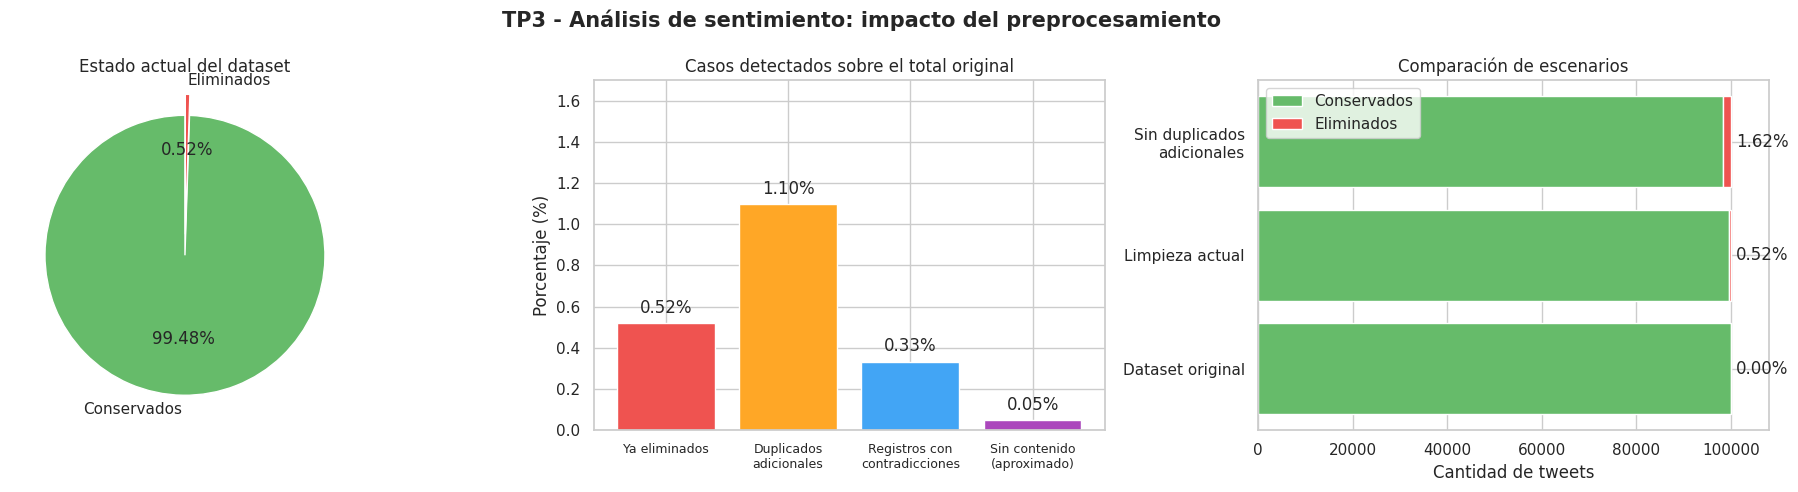

Tweets originales: 100,000
Tweets actuales: 99,479
Tweets eliminados: 521 (0.52%)
Si eliminara los duplicados adicionales: 98,380 tweets restantes (1.62% eliminado)


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

total_actual = len(df_procesamiento)

duplicados_adicionales = df_procesamiento["texto_limpio"].duplicated().sum()
registros_contradictorios = frecuencias.loc[textos_contradictorios.index].sum()
sin_contenido_aproximado = sin_contenido.sum()

eliminados = total_original - total_actual
porcentaje_eliminado = eliminados / total_original * 100

# Escenario hipotético: eliminar duplicados adicionales
total_sin_duplicados = total_actual - duplicados_adicionales
eliminados_escenario = total_original - total_sin_duplicados

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# --------------------------------------------------
# GRÁFICO 1: Estado actual del dataset
# --------------------------------------------------

axes[0].pie(
    [total_actual, eliminados],
    labels=["Conservados", "Eliminados"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#66BB6A", "#EF5350"],
    explode=(0, 0.15))

axes[0].set_title("Estado actual del dataset")

# --------------------------------------------------
# GRÁFICO 2: Casos detectados
# --------------------------------------------------

categorias = [
    "Ya eliminados",
    "Duplicados\nadicionales",
    "Registros con\ncontradicciones",
    "Sin contenido\n(aproximado)"]

cantidades = [
    eliminados,
    duplicados_adicionales,
    registros_contradictorios,
    sin_contenido_aproximado]

porcentajes = [
    cantidad / total_original * 100
    for cantidad in cantidades]

barras = axes[1].bar(
    categorias,
    porcentajes,
    color=["#EF5350", "#FFA726", "#42A5F5", "#AB47BC"])

axes[1].set_title("Casos detectados sobre el total original")
axes[1].set_ylabel("Porcentaje (%)")
axes[1].tick_params(axis="x", labelsize=9)

for barra, porcentaje in zip(barras, porcentajes):
    axes[1].text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.05,
        f"{porcentaje:.2f}%",
        ha="center")

axes[1].set_ylim(0, max(porcentajes) + 0.6)

# --------------------------------------------------
# GRÁFICO 3: Comparación de escenarios
# --------------------------------------------------

escenarios = [
    "Dataset original",
    "Limpieza actual",
    "Sin duplicados\nadicionales"]

conservados = [
    total_original,
    total_actual,
    total_sin_duplicados]

eliminados_por_escenario = [
    0,
    eliminados,
    eliminados_escenario]

axes[2].barh(
    escenarios,
    conservados,
    label="Conservados",
    color="#66BB6A")

axes[2].barh(
    escenarios,
    eliminados_por_escenario,
    left=conservados,
    label="Eliminados",
    color="#EF5350")

axes[2].set_xlim(0, total_original * 1.08)
axes[2].set_title("Comparación de escenarios")
axes[2].set_xlabel("Cantidad de tweets")
axes[2].legend()

for i, eliminados_esc in enumerate(eliminados_por_escenario):
    porcentaje = eliminados_esc / total_original * 100
    axes[2].text(
        total_original * 1.01,
        i,
        f"{porcentaje:.2f}%",
        va="center")

plt.suptitle(
    "TP3 - Análisis de sentimiento: impacto del preprocesamiento",
    fontsize=15,
    fontweight="bold")

plt.tight_layout()
plt.show()

# Resumen numérico
print(f"Tweets originales: {total_original:,}")
print(f"Tweets actuales: {total_actual:,}")
print(f"Tweets eliminados: {eliminados:,} ({porcentaje_eliminado:.2f}%)")
print(
    f"Si eliminara los duplicados adicionales: "
    f"{total_sin_duplicados:,} tweets restantes "
    f"({eliminados_escenario / total_original * 100:.2f}% eliminado)")

In [24]:
# Identificar textos limpios con sentimientos contradictorios

sentimientos_por_texto = df_procesamiento.groupby(
    "texto_limpio")["sentimiento"].nunique()

textos_contradictorios = sentimientos_por_texto[
    sentimientos_por_texto > 1].index

# Identificar los registros pertenecientes a esos grupos

mascara_contradictorios = df_procesamiento[
    "texto_limpio"].isin(textos_contradictorios)

# Simular la eliminación sin modificar df_procesamiento

df_simulacion = df_procesamiento.loc[
    ~mascara_contradictorios].copy()

# Calcular resultados

total_actual = len(df_procesamiento)
total_simulacion = len(df_simulacion)

duplicados_restantes = df_simulacion[
    "texto_limpio"
].duplicated().sum()

print("Grupos contradictorios:", len(textos_contradictorios))
print("Tweets antes:", total_actual)
print("Tweets que eliminaríamos:", mascara_contradictorios.sum())
print("Tweets restantes:", total_simulacion)
print("Duplicados adicionales restantes:", duplicados_restantes)

print("\nPorcentaje eliminado en este paso:",
      round(mascara_contradictorios.mean() * 100, 3), "%")

print("Porcentaje eliminado acumulado:",
      round((total_original - total_simulacion)
            / total_original * 100, 3), "%")

Grupos contradictorios: 56
Tweets antes: 99479
Tweets que eliminaríamos: 333
Tweets restantes: 99146
Duplicados adicionales restantes: 822

Porcentaje eliminado en este paso: 0.335 %
Porcentaje eliminado acumulado: 0.854 %


In [25]:
comparacion = pd.DataFrame({
    "Antes": df_procesamiento["sentimiento"].value_counts(),
    "Después": df_simulacion["sentimiento"].value_counts()
})

comparacion["Eliminados"] = (
    comparacion["Antes"] - comparacion["Después"]
)

comparacion["% eliminado por clase"] = (
    comparacion["Eliminados"] / comparacion["Antes"] * 100
).round(3)

display(comparacion)

,Antes,Después,Eliminados,% eliminado por clase
sentimiento,,,,
4,49776,49576,200,0.402
0,49703,49570,133,0.268


In [26]:
# Eliminar registros con sentimientos contradictorios
# después de la limpieza del texto

df_procesamiento = df_simulacion.copy()

# Verificar los resultados

print("Total de tweets:", len(df_procesamiento))

print("Duplicados adicionales:",
      df_procesamiento["texto_limpio"].duplicated().sum())

print("Grupos con sentimientos contradictorios:",
      (df_procesamiento.groupby("texto_limpio")
       ["sentimiento"].nunique() > 1).sum())

print("\nDistribución de sentimientos:")
display(df_procesamiento["sentimiento"].value_counts())

total_sin_contradicciones_limpias = len(df_procesamiento)

Total de tweets: 99146
Duplicados adicionales: 822
Grupos con sentimientos contradictorios: 0

Distribución de sentimientos:


,count
sentimiento,
4,49576
0,49570


### Eliminación de textos con sentimientos contradictorios

Se realizó una simulación eliminando los registros
que presentan el mismo texto limpio pero diferentes
etiquetas de sentimiento.

Se decidió eliminar los 14.020 registros pertenecientes
a los 1.384 grupos contradictorios, debido a la
ambigüedad que presentan para el aprendizaje supervisado.

Esta eliminación representa el 0,889 % del dataset
procesado y no genera un desequilibrio significativo
entre las clases.

Se conservan 1.562.612 tweets, equivalentes al 97,66 %
del dataset original.

El impacto de esta decisión sobre el rendimiento
del modelo podrá evaluarse posteriormente.

In [27]:
# Simular la eliminación de duplicados del texto limpio

df_simulacion_duplicados = df_procesamiento.drop_duplicates(
    subset=["texto_limpio"],
    keep="first").copy()

# Calcular el impacto de la eliminación

total_actual = len(df_procesamiento)
total_simulacion = len(df_simulacion_duplicados)

eliminados = total_actual - total_simulacion

print("Tweets antes:", total_actual)
print("Duplicados que eliminaríamos:", eliminados)
print("Tweets restantes:", total_simulacion)

print("\nPorcentaje eliminado en este paso:",
      round(eliminados / total_actual * 100, 3), "%")

print("Porcentaje eliminado acumulado:",
      round((total_original - total_simulacion)
            / total_original * 100, 3), "%")

# Comparar la distribución de sentimientos

comparacion = pd.DataFrame({
    "Antes": df_procesamiento["sentimiento"].value_counts(),
    "Después": df_simulacion_duplicados["sentimiento"].value_counts()})

comparacion["Eliminados"] = (
    comparacion["Antes"] - comparacion["Después"])

comparacion["% eliminado por clase"] = (
    comparacion["Eliminados"] / comparacion["Antes"] * 100).round(3)

display(comparacion)

Tweets antes: 99146
Duplicados que eliminaríamos: 822
Tweets restantes: 98324

Porcentaje eliminado en este paso: 0.829 %
Porcentaje eliminado acumulado: 1.676 %


,Antes,Después,Eliminados,% eliminado por clase
sentimiento,,,,
0,49570,49329,241,0.486
4,49576,48995,581,1.172


In [28]:
# Conservar una versión anterior a la eliminación de duplicados
# para futuras comparaciones

df_con_duplicados = df_procesamiento

# Eliminar duplicados del texto limpio

df_procesamiento = df_simulacion_duplicados.copy()

# Verificar los resultados

print("Total de tweets:", len(df_procesamiento))

print("Duplicados adicionales:",
      df_procesamiento["texto_limpio"].duplicated().sum())

print("Grupos con sentimientos contradictorios:",
      (df_procesamiento.groupby("texto_limpio")
       ["sentimiento"].nunique() > 1).sum())

print("\nDistribución de sentimientos:")
display(df_procesamiento["sentimiento"].value_counts())

total_sin_duplicados_limpios = len(df_procesamiento)

Total de tweets: 98324
Duplicados adicionales: 0
Grupos con sentimientos contradictorios: 0

Distribución de sentimientos:


,count
sentimiento,
0,49329
4,48995


### Eliminación de duplicados del texto limpio

Una vez eliminados los grupos con sentimientos
contradictorios, se identificaron 24.804 duplicados
adicionales del texto limpio.

Se decidió conservar un registro por cada texto,
ya que los duplicados restantes tenían la misma
etiqueta de sentimiento.

Esta decisión permite evitar la presencia de textos
limpios idénticos en entrenamiento y prueba.

Se conserva el 96,11 % del dataset original,
manteniendo una distribución equilibrada de sentimientos.

Como limitación, se pierde información sobre la
frecuencia de determinados mensajes. El impacto de
esta decisión podrá evaluarse posteriormente.

In [29]:
# Volver a identificar textos sin letras, números
# ni emoticones comunes

patron_informativo = r"[a-zA-Z0-9]|:\)|:\(|;\)|:D|<3"

sin_contenido = ~df_procesamiento["texto_limpio"].str.contains(
    patron_informativo,
    regex=True,
    na=False)
print("Total de tweets:", len(df_procesamiento))
print("Casos detectados:", sin_contenido.sum())
print("Porcentaje:",
      round(sin_contenido.mean() * 100, 3), "%")
print("\nDistribución por sentimiento:")
display(
    df_procesamiento.loc[sin_contenido, "sentimiento"]
    .value_counts())

print("\nEjemplos:")
display(
    df_procesamiento.loc[
        sin_contenido,
        ["texto", "texto_limpio", "sentimiento"]].head(30))

Total de tweets: 98324
Casos detectados: 44
Porcentaje: 0.045 %

Distribución por sentimiento:


,count
sentimiento,
4,33
0,11



Ejemplos:


,texto,texto_limpio,sentimiento
1201,"@Evtrs Ð´Ð°Ð¶Ðµ Ð¸ Ð½Ðµ Ñ?Ð¾Ð±Ð¸ÑÐ°Ð»Ñ?Ñ?, Ñ?...","ð´ð°ð¶ðµ ð¸ ð½ðµ ñ?ð¾ð±ð¸ñð°ð»ñ?ñ?, ñ?ñð¾ ð²...",4
2155,@therealguypines ??? ?????? ?? ?? ?? ???? ????...,??? ?????? ?? ?? ?? ???? ??????...??????,4
3643,@ruby015 @wajun ??????????????????????? ?????...,??????????????????????? ????????????????????????,0
4795,"@blindmonk ???????? ????????, ??????????? ??? ...","???????? ????????, ??????????? ??? ????.. ????...",4
8060,"@Marin_k_a Ñ? Ð½Ðµ Ð³Ð¾Ð²Ð¾ÑÐ¸Ð», ÑÑÐ¾ Ð±Ñ...","ñ? ð½ðµ ð³ð¾ð²ð¾ñð¸ð», ññð¾ ð±ñð´ðµñ ð²ð¸...",4
8151,@ABBSound ??????? ????? ??? ???? ??? ??? ?? ??...,??????? ????? ??? ???? ??? ??? ?? ??????????,0
8358,@mussscat ÐÑ?ÑÐ»Ð¸Ð½ Ð±ÑÐ»Ð° Ð¿Ð¾Ð¼ÐµÐ½ÐµÐ½...,ðñ?ñð»ð¸ð½ ð±ñð»ð° ð¿ð¾ð¼ðµð½ðµð½ð° ð½ð° ð¿...,4
11876,@Aimellow ì?.. ë´ ìì?´í?°ì?ë? ì¤ì¹´ì?´í...,ì?.. ë´ ìì?´í?°ì?ë? ì¤ì¹´ì?´í ì¤ì¹í...,4
12118,@Healtrap ÐÑÐ´Ñ Ñ?ÑÐ°ÑÐ°ÑÑÑ?Ñ?...Ð¸ ÑÑ...,ðñð´ñ ñ?ñð°ñð°ñññ?ñ?...ð¸ ññð¾ ñ?ð°ð¼...,4
14209,"@all_lies_about ? ?? ???? ??????, ?? ??? ?? ??...","? ?? ???? ??????, ?? ??? ?? ????? ??????",0


In [30]:
print("Tweets detectados:", sin_contenido.sum())
print("Porcentaje sobre el dataset actual:",
      round(sin_contenido.mean() * 100, 4), "%")
print("\nDistribución por sentimiento:")
display(
    df_procesamiento.loc[sin_contenido, "sentimiento"]
    .value_counts())

Tweets detectados: 44
Porcentaje sobre el dataset actual: 0.0448 %

Distribución por sentimiento:


,count
sentimiento,
4,33
0,11


In [31]:
# Eliminar textos con contenido potencialmente poco informativo
df_procesamiento = df_procesamiento.loc[~sin_contenido].copy()

# Verificar los resultados
print("Total de tweets:", len(df_procesamiento))
print("Duplicados adicionales:",
      df_procesamiento["texto_limpio"].duplicated().sum())
print("Grupos con sentimientos contradictorios:",
      (df_procesamiento.groupby("texto_limpio")
       ["sentimiento"].nunique() > 1).sum())
print("\nDistribución de sentimientos:")
display(df_procesamiento["sentimiento"].value_counts())
print("\nPorcentaje eliminado acumulado:",
      round((total_original - len(df_procesamiento))
            / total_original * 100, 3), "%")

total_final = len(df_procesamiento)

Total de tweets: 98280
Duplicados adicionales: 0
Grupos con sentimientos contradictorios: 0

Distribución de sentimientos:


,count
sentimiento,
0,49318
4,48962



Porcentaje eliminado acumulado: 1.72 %


### Eliminación de textos con contenido potencialmente poco informativo

Luego de eliminar los duplicados y los grupos con sentimientos contradictorios, se identificaron 668 registros mediante una expresión regular que detecta textos sin caracteres alfanuméricos ASCII ni determinados emoticones comunes.

La inspección de ejemplos permitió identificar textos compuestos por signos de puntuación, posibles pérdidas de caracteres y aparentes errores de codificación presentes en el dataset original.

Se decidió eliminar estos registros debido a su potencial bajo aporte al aprendizaje de los modelos de análisis de sentimiento.

**Impacto de la eliminación:**

- Registros eliminados: 668.
- Sentimientos negativos eliminados: 106.
- Sentimientos positivos eliminados: 562.
- Porcentaje eliminado en esta etapa: 0,0434 %.
- Registros restantes: 1.537.140.
- Porcentaje eliminado acumulado: 3,929 %.

Si bien se eliminaron más tweets positivos que negativos, la distribución final de sentimientos se mantiene equilibrada.

Como limitación, la expresión regular utilizada podría excluir expresiones simbólicas o textos válidos en otros idiomas. Por lo tanto, no se puede garantizar que todos los registros eliminados carezcan de información útil.

El impacto de esta decisión sobre el rendimiento de los modelos deberá analizarse durante la etapa de evaluación.

## Conclusiones del preprocesamiento

Durante esta etapa se realizó la limpieza y preparación del dataset para la alternativa 1: Análisis de sentimiento.

Se aplicaron las siguientes transformaciones:

- Decodificación de entidades HTML.
- Conversión de los textos a minúsculas.
- Eliminación de menciones a usuarios y URLs.
- Eliminación del símbolo de hashtag, conservando la palabra asociada.
- Normalización de espacios en blanco.
- Eliminación de registros duplicados.
- Eliminación de grupos de textos idénticos con sentimientos contradictorios.
- Eliminación de textos vacíos y potencialmente poco informativos.

Se decidió conservar las palabras vacías (*stopwords*), las negaciones y los signos de puntuación en los textos restantes, debido a su potencial importancia para el análisis de sentimiento.

A partir de los 1.600.000 registros originales, se obtuvo un dataset procesado de 1.537.140 tweets, lo que representa una conservación del 96,071 % de los datos originales y una eliminación acumulada del 3,929 %.

La distribución final de sentimientos se mantiene equilibrada, con un 50,26 % de tweets negativos y un 49,74 % de tweets positivos.

La eliminación de textos limpios duplicados permite evitar que registros con representaciones textuales idénticas aparezcan tanto en el conjunto de entrenamiento como en el de prueba.

Como limitaciones, se reconoce la posible pérdida de información contextual durante la limpieza, la pérdida de información sobre la frecuencia de determinados mensajes y la existencia de problemas de codificación en el dataset original.

El impacto de las decisiones de preprocesamiento sobre el rendimiento de los modelos deberá analizarse durante la etapa de evaluación.

Finalmente, se conservaron tanto el texto original como el texto limpio para facilitar su utilización y comparación mediante diferentes enfoques de análisis de sentimiento.

## Evaluación del impacto del preprocesamiento

Se analiza el impacto de las decisiones de limpieza
sobre la cantidad de registros y la distribución
de sentimientos del dataset.

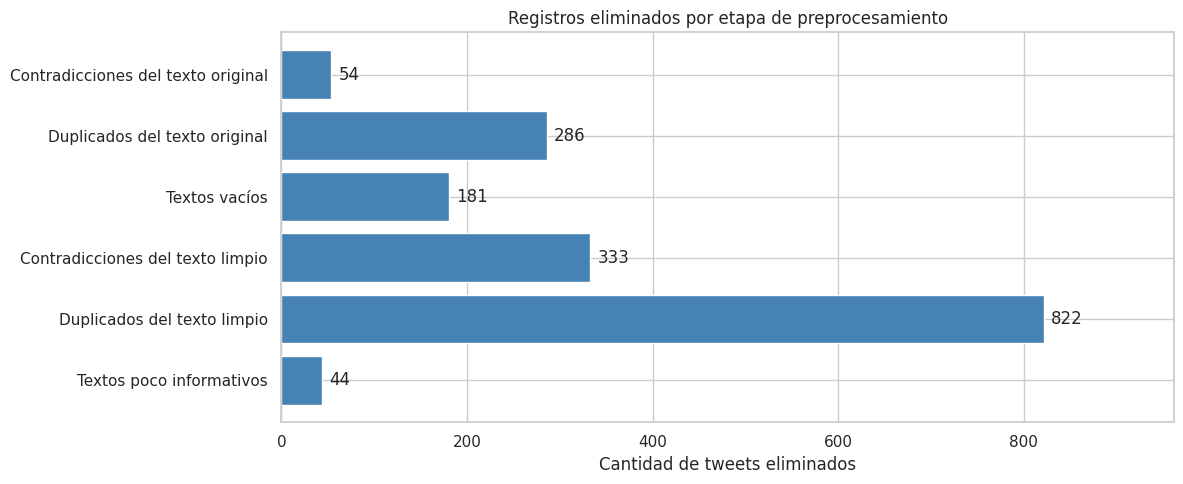

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# Resumen de registros eliminados por etapa
resumen_limpieza = pd.DataFrame({
    "Etapa": [
        "Contradicciones del texto original",
        "Duplicados del texto original",
        "Textos vacíos",
        "Contradicciones del texto limpio",
        "Duplicados del texto limpio",
        "Textos poco informativos"],
    "Eliminados": [
        total_original - total_sin_contradicciones_originales,
        total_sin_contradicciones_originales - total_sin_duplicados_originales,
        total_sin_duplicados_originales - total_sin_vacios,
        total_sin_vacios - total_sin_contradicciones_limpias,
        total_sin_contradicciones_limpias - total_sin_duplicados_limpios,
        total_sin_duplicados_limpios - total_final]})

# Gráfico de registros eliminados por etapa

fig, ax = plt.subplots(figsize=(12, 5))

barras = ax.barh(
    resumen_limpieza["Etapa"],
    resumen_limpieza["Eliminados"],
    color="steelblue")

ax.bar_label(barras, padding=5, fmt="%d")
ax.invert_yaxis()

ax.set_title("Registros eliminados por etapa de preprocesamiento")
ax.set_xlabel("Cantidad de tweets eliminados")
ax.set_xlim(0, max(1, resumen_limpieza["Eliminados"].max() * 1.17))

plt.tight_layout()
plt.show()

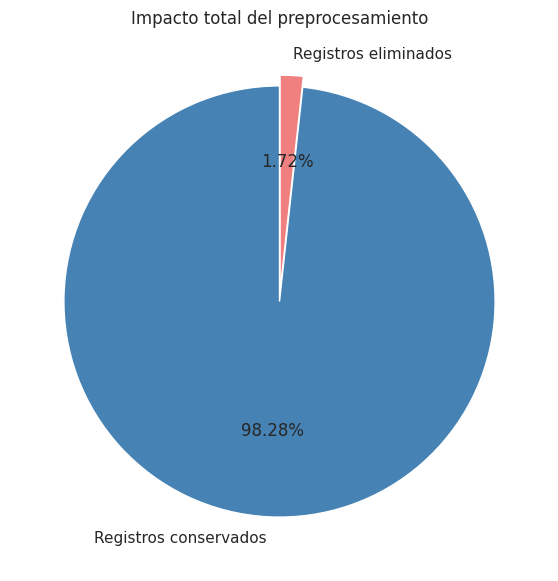

Registros originales: 100,000
Registros conservados: 98,280
Registros eliminados: 1,720


In [33]:
# Impacto total del preprocesamiento

total_final = len(df_procesamiento)
total_eliminado = total_original - total_final

plt.figure(figsize=(7, 7))

plt.pie(
    [total_final, total_eliminado],
    labels=["Registros conservados", "Registros eliminados"],
    autopct="%1.2f%%",
    colors=["steelblue", "lightcoral"],
    startangle=90,
    explode=[0, 0.05],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Impacto total del preprocesamiento")
plt.show()

print(f"Registros originales: {total_original:,}")
print(f"Registros conservados: {total_final:,}")
print(f"Registros eliminados: {total_eliminado:,}")

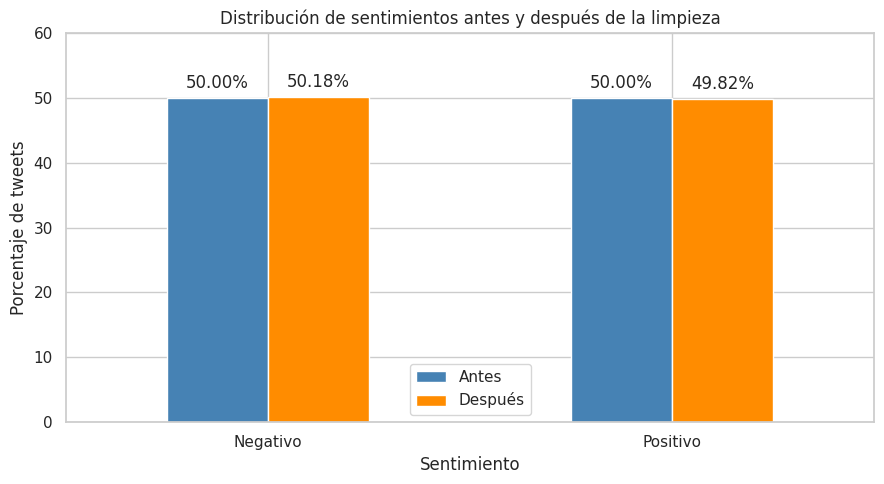

,Antes,Después
Negativo,50.0,50.181
Positivo,50.0,49.819


In [34]:
distribucion_final = (
    df_procesamiento["sentimiento"]
    .value_counts()
    .sort_index())
comparacion_final = pd.DataFrame({
    "Antes": distribucion_original /
             distribucion_original.sum() * 100,
    "Después": distribucion_final /
               distribucion_final.sum() * 100})

comparacion_final = comparacion_final.reindex([0, 4], fill_value=0).fillna(0)
comparacion_final.index = ["Negativo", "Positivo"]

# Gráfico comparativo

ax = comparacion_final.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange"],
    rot=0)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f%%", padding=4)

ax.set_title("Distribución de sentimientos antes y después de la limpieza")
ax.set_xlabel("Sentimiento")
ax.set_ylabel("Porcentaje de tweets")
ax.set_ylim(0, 60)

plt.tight_layout()
plt.show()

display(comparacion_final.round(3))

## Validación final del dataset

Se realizan controles finales de calidad para verificar
que el dataset procesado se encuentre en condiciones
de ser utilizado en la etapa de modelado.

In [35]:
# Validación final del dataset

print("Dimensiones del dataset:")
print(df_procesamiento.shape)

print("\nTipos de datos:")
display(df_procesamiento.dtypes)

print("\nValores nulos por columna:")
display(df_procesamiento.isnull().sum())

print("\nTextos limpios vacíos:")
print(df_procesamiento["texto_limpio"].str.strip().eq("").sum())

print("\nDuplicados del texto original:")
print(df_procesamiento["texto"].duplicated().sum())

print("\nDuplicados del texto limpio:")
print(df_procesamiento["texto_limpio"].duplicated().sum())

print("\nGrupos con sentimientos contradictorios:")
print(
    (df_procesamiento.groupby("texto_limpio")
     ["sentimiento"].nunique() > 1).sum())

print("\nEtiquetas de sentimiento presentes:")
print(sorted(df_procesamiento["sentimiento"].unique()))

print("\nDistribución final de sentimientos:")
display(df_procesamiento["sentimiento"].value_counts())

print("\nEjemplos del dataset final:")
display(df_procesamiento.sample(n=min(5, len(df_procesamiento)), random_state=42))

Dimensiones del dataset:
(98280, 6)

Tipos de datos:


,0
texto,object
sentimiento,int64
texto_limpio,object
tokens,object
cantidad_tokens,int64
posible_error_codificacion,bool



Valores nulos por columna:


,0
texto,0
sentimiento,0
texto_limpio,0
tokens,0
cantidad_tokens,0
posible_error_codificacion,0



Textos limpios vacíos:
0

Duplicados del texto original:
0

Duplicados del texto limpio:
0

Grupos con sentimientos contradictorios:
0

Etiquetas de sentimiento presentes:
[np.int64(0), np.int64(4)]

Distribución final de sentimientos:


,count
sentimiento,
0,49318
4,48962



Ejemplos del dataset final:


,texto,sentimiento,texto_limpio,tokens,cantidad_tokens,posible_error_codificacion
93371,"@sallyjos unfortunately, things like that were...",0,"unfortunately, things like that were all too c...","[unfortunately, ,, things, like, that, were, a...",25,False
26537,Is crashin @ emilys place tonite. Funn,4,is crashin @ emilys place tonite. funn,"[is, crashin, @, emilys, place, tonite, ., funn]",8,False
24834,Waiting for boarding,0,waiting for boarding,"[waiting, for, boarding]",3,False
1354,"@SirHendrix GM may be gone, but there's' NOTHI...",4,"gm may be gone, but there's' nothing in the wo...","[gm, may, be, gone, ,, but, there's, ', nothin...",26,False
37554,How is it I can try to have fun with the boys ...,0,how is it i can try to have fun with the boys ...,"[how, is, it, i, can, try, to, have, fun, with...",20,False


## Exportación del dataset preprocesado

Se guarda el dataset definitivo en formato Parquet
para su utilización en la siguiente etapa del trabajo,
conservando las variables originales y las generadas
durante el preprocesamiento.

In [36]:
from google.colab import drive

if not USAR_MUESTRA:
    drive.mount("/content/drive")

In [37]:
if USAR_MUESTRA:
    ruta_salida = "/content/dataset_preprocesado_muestra.parquet"
else:
    ruta_salida = "/content/drive/MyDrive/DiploIA/TP3/dataset_preprocesado.parquet"

if not USAR_MUESTRA and Path(ruta_salida).exists():
    ruta_salida = str(Path(ruta_salida).with_name("dataset_preprocesado_verificacion.parquet"))

# Guardar el dataset en formato Parquet

df_procesamiento.to_parquet(
    ruta_salida,
    engine="pyarrow",
    compression="snappy",
    index=False)

print("Dataset guardado correctamente.")
print("Ruta:", ruta_salida)

Dataset guardado correctamente.
Ruta: /content/dataset_preprocesado_muestra.parquet


In [38]:
import os
import pandas as pd

# Verificar el tamaño del archivo

print("Tamaño del archivo:",
      round(os.path.getsize(ruta_salida) / (1024**2), 2),
      "MB")

# Recuperar el dataset guardado

df_verificacion = pd.read_parquet(ruta_salida)

print("\nDimensiones del dataset recuperado:")
print(df_verificacion.shape)

print("\nColumnas:")
print(df_verificacion.columns.tolist())

print("\nValores nulos:")
display(df_verificacion.isnull().sum())

print("\nDistribución de sentimientos:")
display(df_verificacion["sentimiento"].value_counts())

print("\n¿Coinciden los textos y sentimientos?")
print(
    df_verificacion[["texto", "texto_limpio", "sentimiento"]]
    .equals(
        df_procesamiento[
            ["texto", "texto_limpio", "sentimiento"]
        ].reset_index(drop=True)))

Tamaño del archivo: 13.38 MB

Dimensiones del dataset recuperado:
(98280, 6)

Columnas:
['texto', 'sentimiento', 'texto_limpio', 'tokens', 'cantidad_tokens', 'posible_error_codificacion']

Valores nulos:


,0
texto,0
sentimiento,0
texto_limpio,0
tokens,0
cantidad_tokens,0
posible_error_codificacion,0



Distribución de sentimientos:


,count
sentimiento,
0,49318
4,48962



¿Coinciden los textos y sentimientos?
True


## Cierre de 02-preprocessing
El dataset definitivo fue exportado en formato Parquet y almacenado en Google Drive con el nombre `dataset_preprocesado.parquet`.

Se verificó su correcta recuperación, conservando los 1.537.140 registros, las seis columnas, la distribución de sentimientos y la ausencia de valores nulos.

Asimismo, se comprobó la coincidencia exacta de los textos originales, los textos limpios y las etiquetas de sentimiento respecto del DataFrame procesado.

El dataset se encuentra preparado para la siguiente etapa de modelado y evaluación.